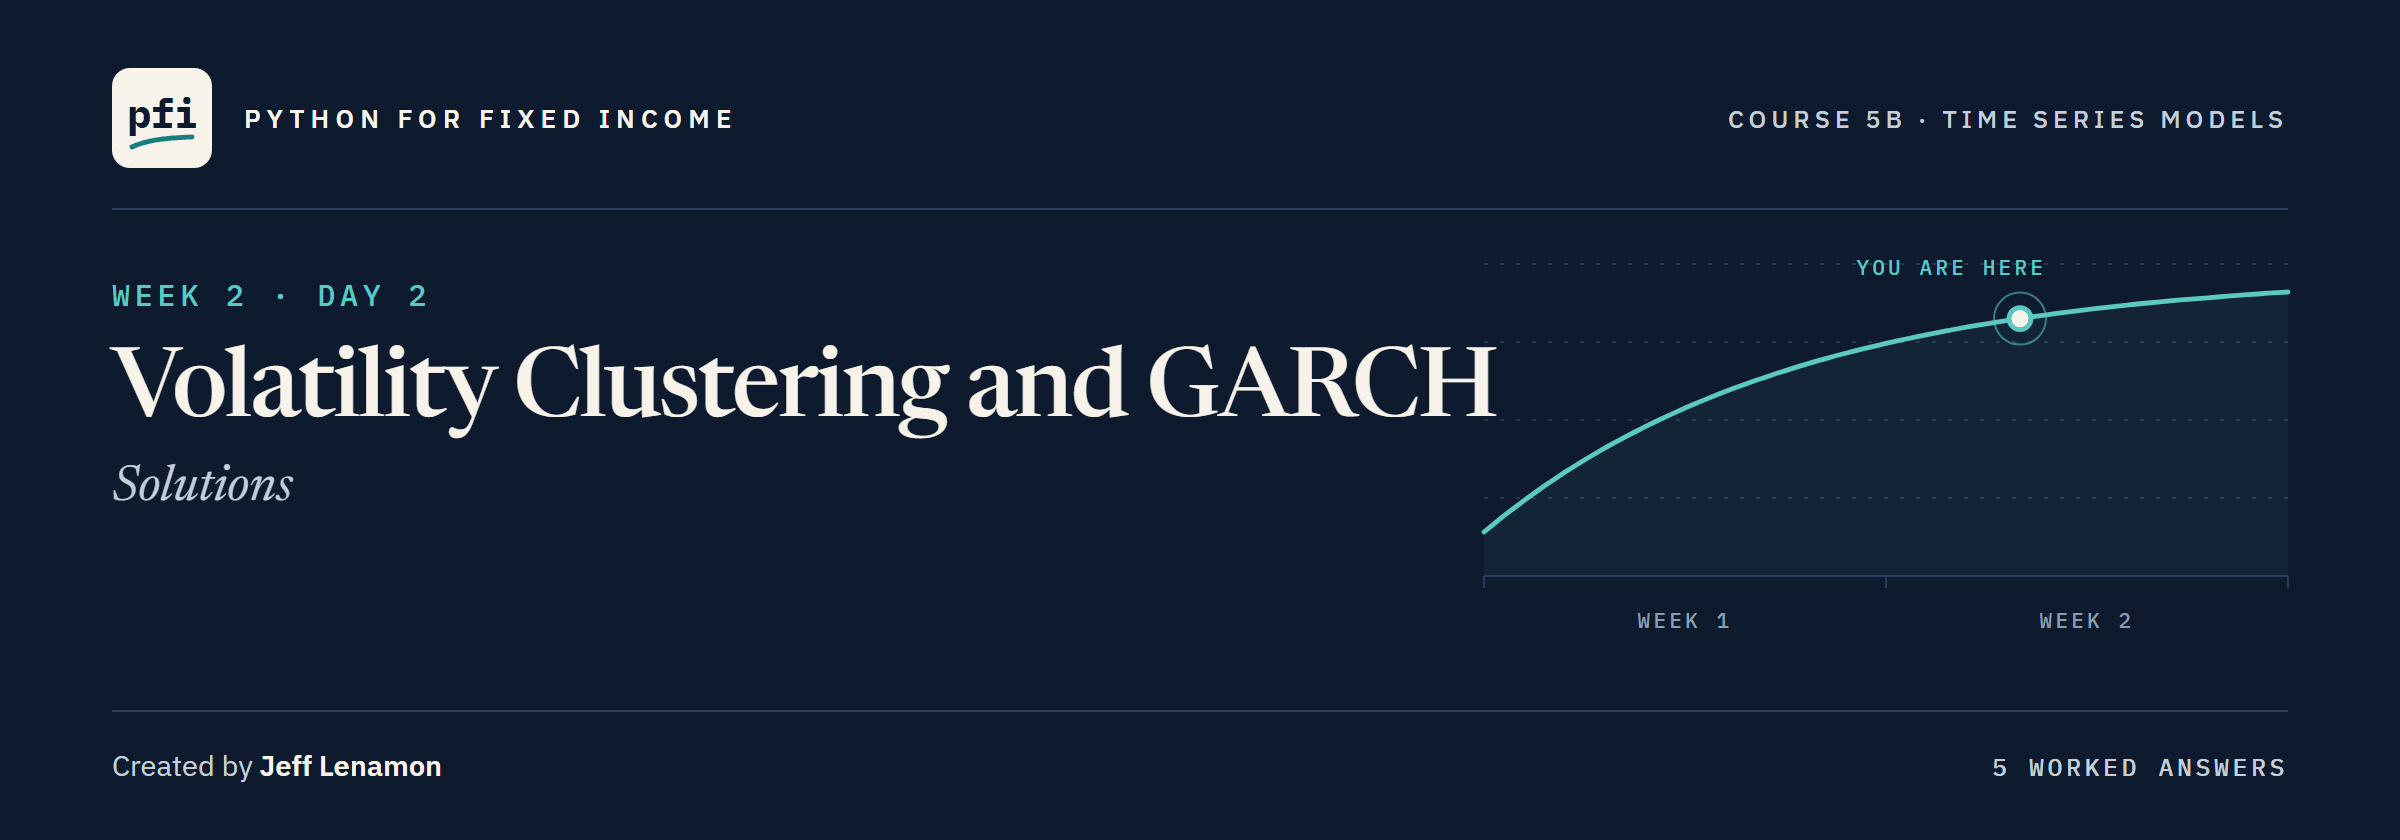

# Volatility Clustering and GARCH: Solutions

Week 2, Day 2. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day2/07_volatility_clustering_and_garch_solutions.ipynb)

# Problem Statement

## Business Context

Days 4 and 6 found memory in the size of a daily change: its square remembers the days before, and an EWMA of the size follows it.
A risk desk wants one model of that size it can read: how stormy a date was, from earlier dates only, and how long a storm takes to fade.
Today fits GARCH(1,1) to the five series' daily changes with arch, reads each of its numbers, checks its shocks, and scores it walk-forward beside Day 6's EWMA.
A fitted volatility describes the file's past dates; it is never a risk call and never a forecast.

## Objectives

Measure how a series' largest days sit in time, write the GARCH(1,1) variance recursion by hand and match arch, and read omega, alpha, beta, persistence, half-life and long-run volatility.
Compare three measures of volatility, choose the shock curve and the variance model by AIC and BIC, score a one-step volatility walk-forward on the size of a change, and set the size beside the level.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, 2015-01-02 to 2026-10-02
2. `2 Yr`, `10 Yr`: par yields, percent (the other twelve tenors are not used today)

`course3_synthetic_spreads.csv`, one row per trading day of the Treasury file:

1. `ig_spread_bp`, `hy_spread_bp`: investment grade and high yield spreads, bp

Made in the notebook, as on Day 2: the five series in bp on the development years, their daily changes, and the size of each change (its absolute value, bp).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data, and the normal and t curves
import numpy as np
import pandas as pd
from scipy import stats

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# Day 2's folds and score, Day 4's autocorrelation, and Day 5's ARIMA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.arima.model import ARIMA

# GARCH models, and a way to hold an optimiser to one thread, so its last digits are the same on every run
from arch import arch_model
from threadpoolctl import threadpool_limits

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Two Files and Cutting the Years

In [3]:
# the Treasury par yields in percent and the synthetic spreads in bp, one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: the development years only, so the held-out years stay closed
CUT = "2022-12-30"
development = yields.loc[:CUT]

In [4]:
# Day 2's five series, all in bp: a yield in percent times 100, the slope as 10 Yr less 2 Yr
levels = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# each day's change in bp: the level less the level one row before
changes = levels.diff().dropna()
print(len(levels), "levels and", len(changes), "changes, from", changes.index[0].date(), "to", changes.index[-1].date())

2001 levels and 2000 changes, from 2015-01-05 to 2022-12-30


## The Five Folds

In [5]:
# Day 2's five walk-forward folds: 252 test dates each, every training window starting on the first change
folds = list(TimeSeriesSplit(n_splits=5, test_size=252).split(changes))
scored = changes.index[folds[0][1][0]:]
print("Fold 1 trains on", len(folds[0][0]), "changes | scored dates:", len(scored), "from", scored[0].date())

Fold 1 trains on 740 changes | scored dates: 1260 from 2017-12-15


**Today models the size of each change, never its level.**

# Data Overview

## Checking the Statistical Summary

In [6]:
changes.describe().round(2)

,2 Yr,10 Yr,2s10s,IG,HY
count,2000.00,2000.00,2000.00,2000.00,2000.00
mean,0.19,0.09,-0.10,0.02,0.05
std,4.19,5.03,3.32,1.19,5.01
min,-27.00,-30.00,-16.00,-7.00,-23.00
25%,-2.00,-3.00,-2.00,-0.70,-2.80
50%,0.00,0.00,0.00,0.00,0.00
75%,2.00,3.00,2.00,0.60,2.80
max,34.00,29.00,18.00,9.80,42.90


The 10 Yr's changes run from -30 to +29 bp around a mean near zero, with a standard deviation of 5.03 bp.

IG moves least, with a standard deviation of 1.19 bp; HY's largest change is +42.9 bp.

## Checking the Tails

**Excess kurtosis** measures how heavy a curve's tails are beside the normal curve's, which scores 0.
`stats.kurtosis` from SciPy gives it, and `stats.norm.sf(3)` is the share of a normal curve above 3 standard deviations.

In [7]:
# excess kurtosis of each series' changes: 0 for a normal curve, higher when the tails are heavier
changes.apply(stats.kurtosis).round(2)

2 Yr     7.68
10 Yr    2.83
2s10s    2.13
IG       7.14
HY       6.33
dtype: float64

In [8]:
# the 10 Yr's changes more than 3 standard deviations from their mean, and how many a normal curve expects
ten = changes["10 Yr"]
beyond = ((ten - ten.mean()).abs() > 3 * ten.std()).sum()
print("Beyond 3 standard deviations:", beyond, "| a normal curve expects:", round(len(ten) * 2 * stats.norm.sf(3), 1))

Beyond 3 standard deviations: 26 | a normal curve expects: 5.4


Every series has heavier tails than a normal curve, the 2 Yr's heaviest.

The 10 Yr has 26 changes beyond 3 standard deviations, about five times what one bell curve allows.

**Too many large days for one bell curve; next, whether they scatter or sit together.**

# Exploratory Data Analysis

## Where the Largest Days Fall

The **size** of a change is its absolute value in bp: how far the series moved, whichever way.
`Index.to_period("M")` turns each date into its month.

In [9]:
# the size of each 10 Yr change in bp, and the month of each date
size = ten.abs()
months = ten.index.to_period("M")

# 1,000 draws of 100 dates at random (Course 4's rng.choice): how many months each draw lands in
rng = np.random.default_rng(SEED)
random_months = [months[rng.choice(len(ten), size=100, replace=False)].nunique() for i in range(1000)]
print("Months:", months.nunique(), "| 100 random dates land in", np.mean(random_months), "months on average,",
      min(random_months), "to", max(random_months))

Months: 96 | 100 random dates land in 63.135 months on average, 50 to 74


**Predict 1**

Scattered at random, 100 dates land in about 63 of the 96 months.

Q. How many months hold the 10 Yr's 100 largest days? Write down a number.

## The 100 Largest Days

In [10]:
# the 100 largest sizes, the smallest of them, the months they fall in, and how many fall in each year
largest = size.nlargest(100)
print("Smallest of the 100:", largest.min(), "bp | months:", largest.index.to_period("M").nunique())
print("By year:", largest.groupby(largest.index.year).size().to_dict())

Smallest of the 100: 10.0 bp | months: 43
By year: {2015: 20, 2016: 9, 2017: 2, 2018: 2, 2019: 11, 2020: 15, 2021: 4, 2022: 37}


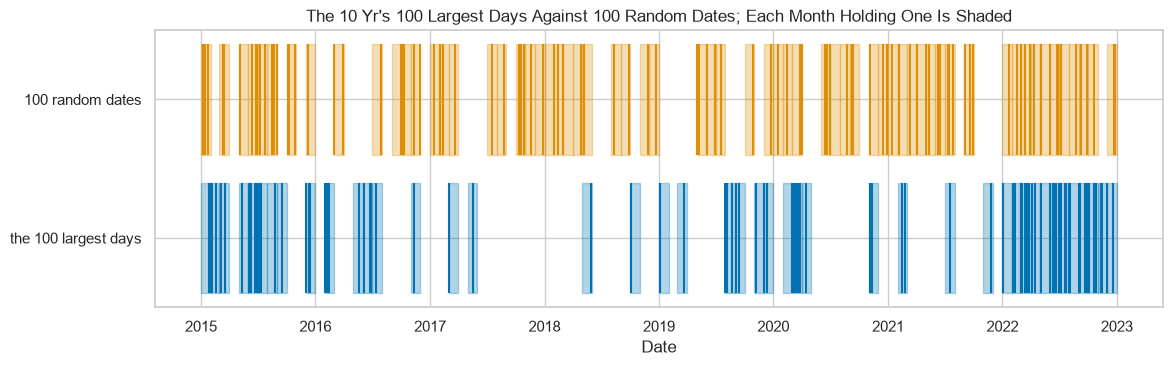

In [11]:
# the 100 largest days against one random draw of 100 dates, each month that holds one of them shaded
draw = ten.index[rng.choice(len(ten), size=100, replace=False)]
fig, ax = plt.subplots(figsize=(13, 3.6))
for row, dates in enumerate([largest.index, draw]):
    for month in dates.to_period("M").unique():
        ax.axvspan(month.start_time, month.end_time, ymin=row / 2 + 0.05, ymax=row / 2 + 0.45, color=f"C{row}", alpha=0.3)
ax.eventplot([largest.index, draw], lineoffsets=[0.5, 1.5], linelengths=0.8, colors=["C0", "C1"])
ax.set(ylim=(0, 2), yticks=[0.5, 1.5], yticklabels=["the 100 largest days", "100 random dates"], xlabel="Date")
ax.set_title("The 10 Yr's 100 Largest Days Against 100 Random Dates; Each Month Holding One Is Shaded")
plt.show()

The 100 largest days sit in 43 months; none of the 1,000 random draws landed in fewer than 50.

By year: 20, 9, 2, 2, 11, 15, 4 and 37 from 2015 to 2022, with 2022 alone holding 37.

## A Day's Size Against the 20 Before

In [12]:
# the average size of the 20 changes before each date, in bp: shift(1) first, so a date never reads itself
before = size.shift(1).rolling(20).mean()

# the dates in ten equal groups by that average (Course 1's qcut), and each group's average size on the date itself
tenth = pd.qcut(before, 10, labels=range(1, 11))
by_tenth = size.groupby(tenth, observed=True).mean()
print(by_tenth.round(2).to_dict(), "| all dates:", round(size.mean(), 2))

{1: 2.57, 2: 2.88, 3: 2.94, 4: 3.05, 5: 3.49, 6: 3.64, 7: 3.47, 8: 4.02, 9: 5.13, 10: 6.46} | all dates: 3.75


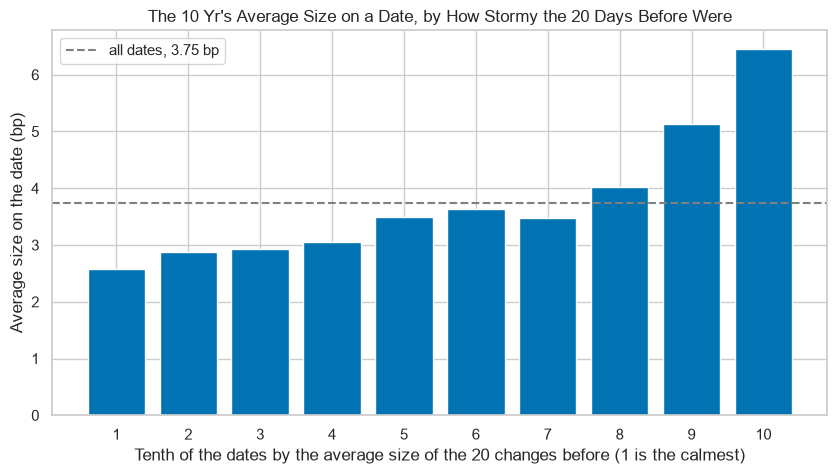

In [13]:
# each tenth's average size, with the average of all dates dashed
plt.bar(range(1, 11), by_tenth, color="C0")
plt.axhline(size.mean(), color="gray", linestyle="--", label=f"all dates, {size.mean():.2f} bp")
plt.xticks(range(1, 11))
plt.xlabel("Tenth of the dates by the average size of the 20 changes before (1 is the calmest)")
plt.ylabel("Average size on the date (bp)")
plt.title("The 10 Yr's Average Size on a Date, by How Stormy the 20 Days Before Were")
plt.legend()
plt.show()

In [14]:
# Day 4's autocorrelation at lag 1: the change, its size and its square
print("Change:", round(acf(ten.to_numpy(), nlags=1)[1], 3), "| size:", round(acf(size.to_numpy(), nlags=1)[1], 3),
      "| square:", round(acf((ten ** 2).to_numpy(), nlags=1)[1], 3))

Change: -0.007 | size: 0.211 | square: 0.225


After the calmest 20 days the next change averages 2.57 bp; after the stormiest, 6.46.

As Day 4 found, the change hardly remembers the day before, and its size and square do.

**The sign forgets; the size remembers. A model of the size needs a variance that carries yesterday into today.**

# How GARCH Works

![One row of the GARCH(1,1) recursion: three boxes, omega, alpha times yesterday's shock squared, and beta times yesterday's variance, add into today's variance; its square root is today's volatility in bp; one row later today's variance becomes yesterday's. A shock is the change less its mean, and every term reads only rows before today](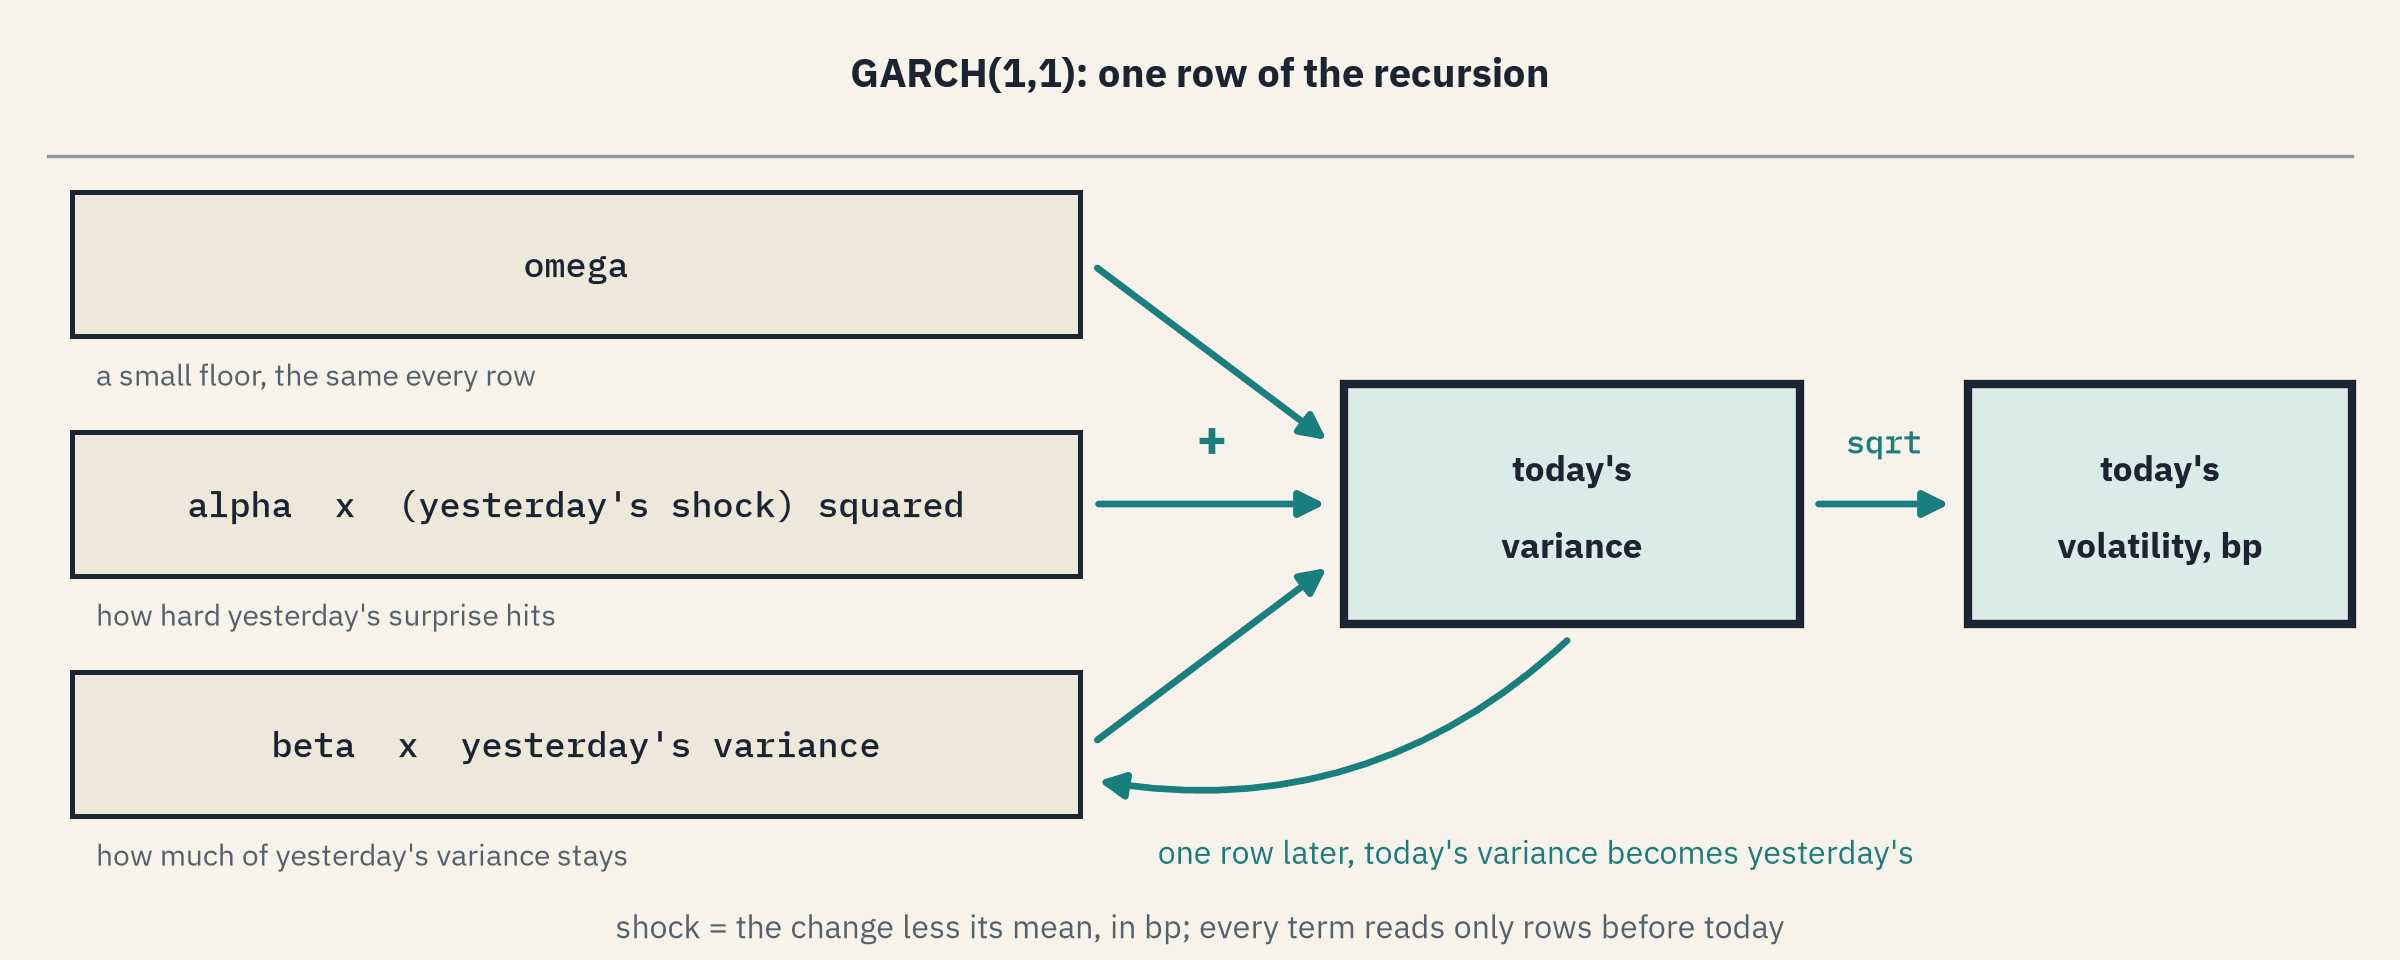)

A **shock** is a change less its mean, in bp.
The **conditional variance** of a date is the variance of its shock given every earlier row, and its square root is the date's **volatility**, in bp.
**GARCH(1,1)** (generalised autoregressive conditional heteroskedasticity) builds each date's variance from three numbers.

**omega**: a small floor, the same on every row.

**alpha**: the weight on yesterday's squared shock.

**beta**: the weight on yesterday's variance.

## Your Turn: Set Alpha and Beta

In [15]:
# 1,000 draws from the normal curve, the same for every setting
draws = rng.standard_normal(1000)

# a GARCH(1,1) path: each change is the volatility times a draw; omega is set so the volatility settles at 2 bp
def make_path(alpha, beta):
    omega = 4 * (1 - alpha - beta)
    variance, path = [4.0], []
    for draw in draws:
        path.append(np.sqrt(variance[-1]) * draw)
        variance.append(omega + alpha * path[-1] ** 2 + beta * variance[-1])
    return np.array(path), np.sqrt(variance[:-1])

In [16]:
# one setting's path and volatility; beta is capped so alpha + beta stays below 1
def draw_garch(alpha=0.05, beta=0.90):
    beta = min(beta, 0.99 - alpha)
    path, volatility = make_path(alpha, beta)
    plt.figure(figsize=(12, 4))
    plt.plot(path, color="gray", linewidth=0.6, label="change (bp)")
    plt.plot(volatility, color="C0", label="volatility (bp)")
    plt.title(f"Alpha + Beta = {alpha + beta:.2f}")
    plt.xlabel("Row")
    plt.ylabel("bp")
    plt.legend(loc="upper right")
    plt.show()

In [17]:
# your turn: move alpha and beta, and watch the storms come and go
interact(draw_garch, alpha=(0.0, 0.3, 0.01), beta=(0.0, 0.98, 0.01));

interactive(children=(FloatSlider(value=0.05, description='alpha', max=0.3, step=0.01), FloatSlider(value=0.9,…

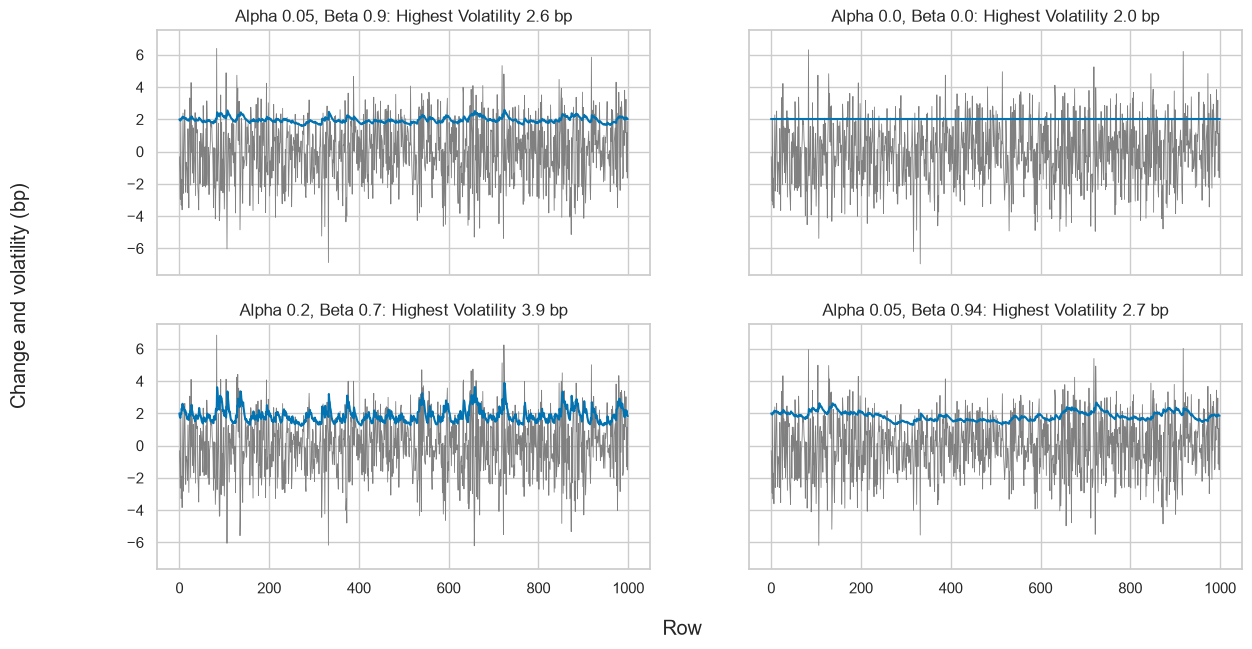

In [18]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
# with three more settings beside it, each titled with its highest volatility
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, (alpha, beta) in zip(axes.flat, [(0.05, 0.90), (0.0, 0.0), (0.20, 0.70), (0.05, 0.94)]):
    path, volatility = make_path(alpha, beta)
    ax.plot(path, color="gray", linewidth=0.6)
    ax.plot(volatility, color="C0")
    ax.set_title(f"Alpha {alpha}, Beta {beta}: Highest Volatility {volatility.max():.1f} bp")
fig.supxlabel("Row")
fig.supylabel("Change and volatility (bp)")
plt.show()

With alpha and beta at 0 the volatility is a flat 2 bp: every day is drawn from the same curve.

A large alpha makes sharp spikes that fade within days; a large beta with a small alpha makes long storms.

## How Long a Shock Lasts

The **persistence** is alpha + beta: the share of a shock's extra variance, above the long-run level, still there one row later.

**Predict 2**

A persistence of 0.9809 keeps 98.09 percent of a shock's extra variance each row.

Q. How many rows until half of it is gone? Write down a number.

## The Half-Life of a Shock

The **half-life** is the number of rows n at which persistence to the power n is 0.5: n = ln 0.5 / ln(persistence).

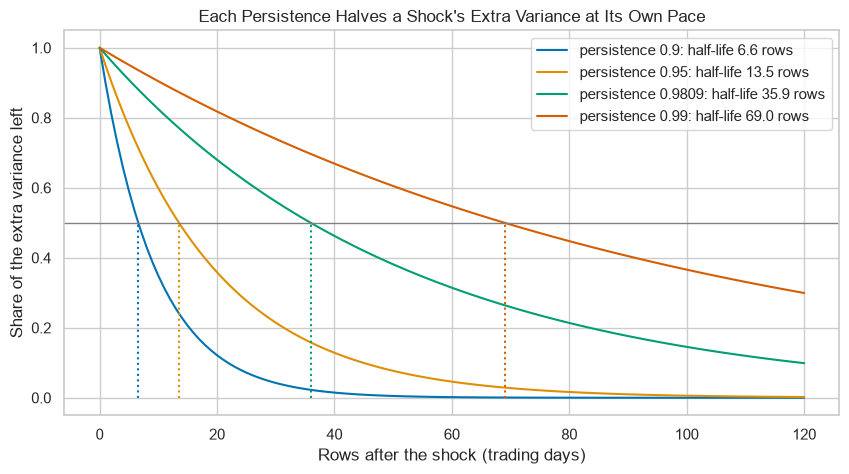

In [19]:
# the share of a shock's extra variance left after each row, with each half-life dropped to the axis
rows_after = np.arange(121)
for persistence, colour in zip([0.90, 0.95, 0.9809, 0.99], ["C0", "C1", "C2", "C3"]):
    half_life = np.log(0.5) / np.log(persistence)
    plt.plot(rows_after, persistence ** rows_after, color=colour, label=f"persistence {persistence}: half-life {half_life:.1f} rows")
    plt.vlines(half_life, 0, 0.5, color=colour, linestyle=":")
plt.axhline(0.5, color="gray", linewidth=1)
plt.xlabel("Rows after the shock (trading days)")
plt.ylabel("Share of the extra variance left")
plt.title("Each Persistence Halves a Shock's Extra Variance at Its Own Pace")
plt.legend()
plt.show()

At 0.9809 half the extra variance is gone after 35.9 rows, about seven weeks of trading days.

From 0.99 to 0.90 the half-life falls from 69 rows to under 7.

**Alpha says how hard a shock hits; persistence says how long it stays.**

# Fitting GARCH(1,1)

## The 10 Yr's 2,000 Changes

`arch_model(values, mean="Constant", vol="GARCH", p=1, q=1, rescale=False)` from arch sets the model: a constant mean **mu**, and a GARCH variance with one lag of the squared shock (`p`) and one of the variance (`q`).
`rescale=False` keeps the changes in bp, and `.fit(disp="off")` fits by maximum likelihood (Course 4's Day 6) without printing the optimiser's report.
`with threadpool_limits(limits=1):` runs the fit on one thread.

In [20]:
# a GARCH(1,1) on the 10 Yr's 2,000 changes in bp
garch_model = arch_model(ten.to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
with threadpool_limits(limits=1):
    garch = garch_model.fit(disp="off")

# each fitted number with its standard error
pd.DataFrame({"estimate": garch.params, "standard error": garch.std_err}).round(4)

,estimate,standard error
mu,0.0715,0.0929
omega,0.4668,0.2421
alpha[1],0.0658,0.0171
beta[1],0.9151,0.0248


### Interpretation of the Coefficients

The **long-run volatility**, sqrt(omega / (1 - alpha - beta)), is the level the volatility settles at once the shocks die away.

In [21]:
# persistence, the half-life of a shock, and the long-run volatility, in bp
mu, omega, alpha, beta = garch.params
persistence = alpha + beta
print("Persistence:", round(persistence, 4), "| half-life:", round(np.log(0.5) / np.log(persistence), 1), "rows")
print("Long-run volatility:", round(np.sqrt(omega / (1 - persistence)), 2), "bp | standard deviation of the changes:",
      round(ten.std(), 2), "bp")

Persistence: 0.9809 | half-life: 35.9 rows
Long-run volatility: 4.94 bp | standard deviation of the changes: 5.03 bp


In [22]:
# the fitted volatility of each date, in bp, with its dates put back
volatility = pd.Series(garch.conditional_volatility, index=ten.index)
print("Lowest:", round(volatility.min(), 2), "bp on", volatility.idxmin().date(), "| highest:",
      round(volatility.max(), 2), "bp on", volatility.idxmax().date())

Lowest: 3.0 bp on 2020-10-05 | highest: 12.94 bp on 2020-03-24


Alpha is 0.066: a shock of 10 bp adds 6.6 bp squared to the next day's variance.

Beta is 0.915, so the persistence is 0.981 and a shock's extra variance halves in 35.9 trading days.

The long-run volatility, 4.94 bp, sits near the changes' standard deviation of 5.03.

The fitted volatility ran from 3.00 bp in October 2020 to 12.94 bp on 2020-03-24.

## The Recursion by Hand

`garch_path` writes the recursion out, starting from arch's own first variance.

In [23]:
# the GARCH(1,1) recursion: each row's variance from the row before
def garch_path(values, mu, omega, alpha, beta, first_variance):
    variance = [first_variance]
    for value in values[:-1]:
        variance.append(omega + alpha * (value - mu) ** 2 + beta * variance[-1])
    return np.sqrt(variance)

by_hand = garch_path(ten.to_numpy(), mu, omega, alpha, beta, volatility.iloc[0] ** 2)
print("Equal to arch's:", np.allclose(by_hand, volatility), "| largest gap:", np.abs(by_hand - volatility).max(), "bp")

Equal to arch's: True | largest gap: 0.0 bp


In [24]:
# Day 2's cut test: blank every change from 2019-12-31 on, run the recursion again, compare up to and including the cut
blanked = ten.copy()
blanked.loc["2019-12-31":] = np.nan
stopped = garch_path(blanked.to_numpy(), mu, omega, alpha, beta, volatility.iloc[0] ** 2)
whole, stopped = pd.Series(by_hand, index=ten.index)[:"2019-12-31"], pd.Series(stopped, index=ten.index)[:"2019-12-31"]
print("equal:", whole.equals(stopped), "|", len(whole.compare(stopped)), "of", len(whole), "values moved")

equal: True | 0 of 1249 values moved


Five lines give arch's 2,000 volatilities to the last digit.

No value up to the cut moves: a date's volatility reads only the shocks before it.

The three numbers came from all 2,000 changes, so this fit describes the years; the walk-forward section fits them on earlier dates only.

## The Same Model on Five Series

In [25]:
# the same GARCH(1,1) on each series: its fitted numbers, and its fitted volatility with the dates put back
rows, vols, plain_bic = [], {}, {}
for name in changes.columns:
    series_model = arch_model(changes[name].to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
    with threadpool_limits(limits=1):
        series_fit = series_model.fit(disp="off")
    rows.append(series_fit.params.rename(name))
    vols[name] = pd.Series(series_fit.conditional_volatility, index=changes.index)
    plain_bic[name] = series_fit.bic

In [26]:
# persistence and half-life for each series; a persistence of 1 or more has no half-life
five = pd.DataFrame(rows)
five["persistence"] = five["alpha[1]"] + five["beta[1]"]
five["half-life"] = np.log(0.5) / np.log(five["persistence"].where(five["persistence"] < 1))
print("The 2 Yr's alpha + beta:", f"{five.loc['2 Yr', 'persistence']:.10f}")
five.round(4)

The 2 Yr's alpha + beta: 1.0000000087


,mu,omega,alpha[1],beta[1],persistence,half-life
2 Yr,0.1044,0.0775,0.0978,0.9022,1.0000,NaN
10 Yr,0.0715,0.4668,0.0658,0.9151,0.9809,35.9495
2s10s,-0.0903,0.0775,0.0428,0.9507,0.9936,107.4889
IG,0.0178,0.0546,0.1275,0.8298,0.9573,15.8987
HY,0.0820,0.8014,0.1299,0.8360,0.9659,20.0075


A **horizon chart** folds a line into bands of one unit each and stacks them in deepening shades, so several series fit in a few rows: the darker a stretch, the stormier.

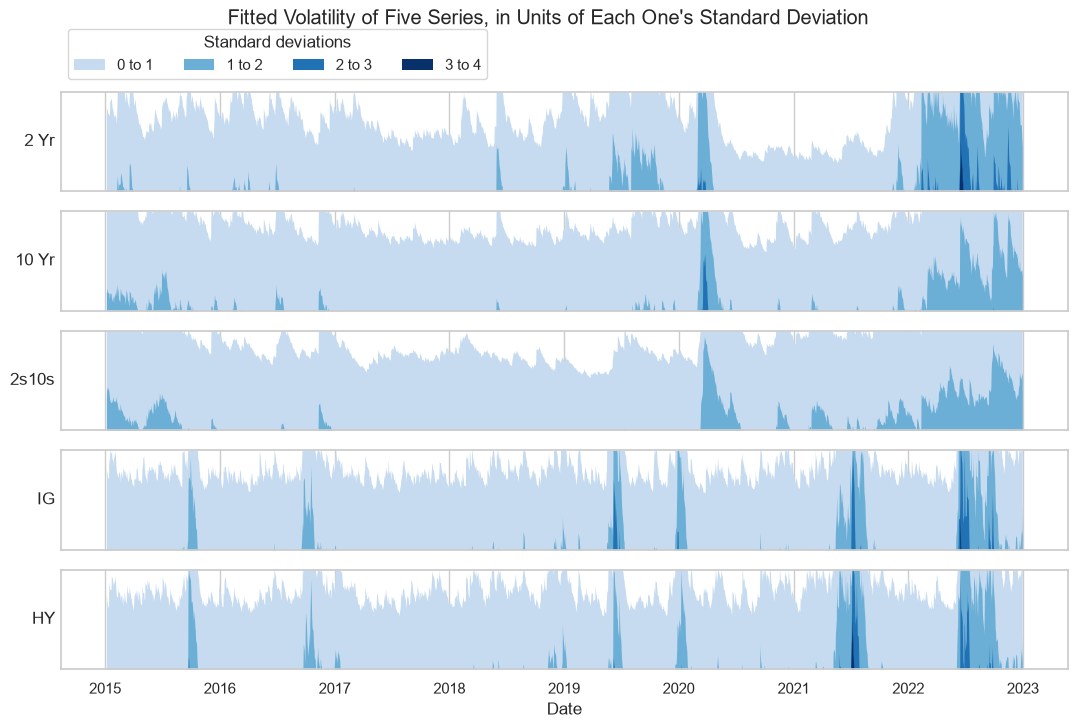

In [27]:
# each series' fitted volatility over its own standard deviation, folded into bands of one unit
fig, axes = plt.subplots(5, 1, figsize=(13, 7.5), sharex=True)
for ax, name in zip(axes, changes.columns):
    units = vols[name] / changes[name].std()
    for band, shade in enumerate(["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
        ax.fill_between(units.index, 0, (units - band).clip(0, 1), color=shade, linewidth=0, label=f"{band} to {band + 1}")
    ax.set(ylim=(0, 1), yticks=[])
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[0].legend(title="Standard deviations", ncols=4, loc="lower left", bbox_to_anchor=(0, 1.05))
axes[-1].set_xlabel("Date")
fig.suptitle("Fitted Volatility of Five Series, in Units of Each One's Standard Deviation", y=0.99)
plt.show()

The 2 Yr, 10 Yr and 2s10s darken in March 2020 and again through 2022; the synthetic IG and HY have storms of their own, darkest in mid-2021 and mid-2022.

Persistence runs from 0.957 (IG, a half-life of 15.9 rows) to 0.994 (2s10s, 107 rows).

The 2 Yr's alpha + beta sits on 1, the most arch allows, to the optimiser's last digits: in this fit a shock's extra variance never fades, so it has no half-life and no long-run volatility.

**Three numbers describe each series' storms; in the 2 Yr's fit, a storm never fades.**

# Three Volatilities on One Chart

## Rolling, RiskMetrics and GARCH

Course 3's rolling volatility is the standard deviation of the last 20 changes, and Day 6's RiskMetrics volatility is the EWMA of squared changes at lambda 0.94.
Each is shifted one row, so like GARCH's it reads only the rows before a date.

In [28]:
# three volatilities of the 10 Yr for each date, in bp, each from the rows before it
three = pd.DataFrame({"rolling 20": ten.rolling(20).std().shift(1),
                      "RiskMetrics": np.sqrt((ten ** 2).ewm(alpha=0.06, adjust=False).mean().shift(1)),
                      "GARCH": volatility})
print(three.corr().round(3))
print("Highest in 2020:", three.loc["2020"].max().round(2).to_dict())

             rolling 20  RiskMetrics  GARCH
rolling 20        1.000        0.959  0.961
RiskMetrics       0.959        1.000  0.987
GARCH             0.961        0.987  1.000
Highest in 2020: {'rolling 20': 14.51, 'RiskMetrics': 13.14, 'GARCH': 12.94}


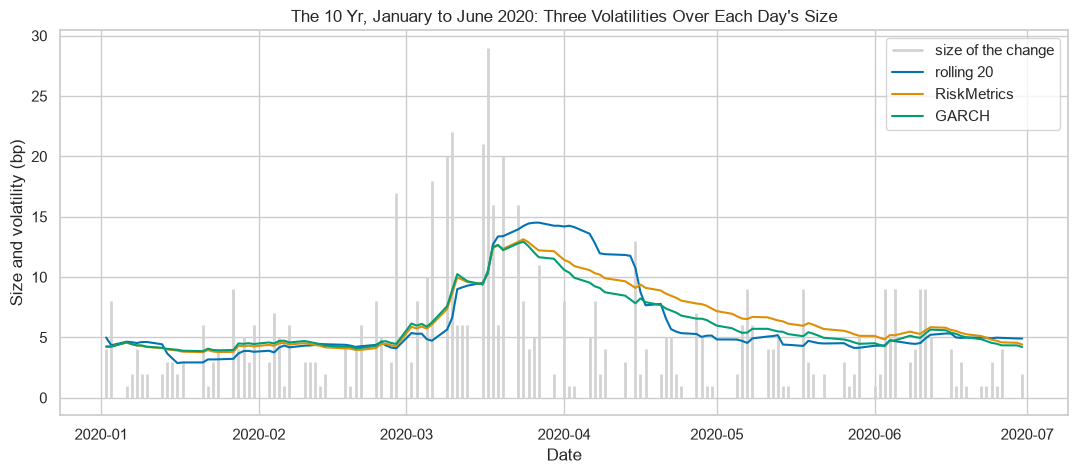

In [29]:
# January to June 2020: each day's size as a gray spike, the three volatilities as lines
spring = three.loc["2020-01":"2020-06"]
fig, ax = plt.subplots(figsize=(13, 5))
ax.vlines(spring.index, 0, size.loc[spring.index], color="lightgray", linewidth=2, label="size of the change")
ax.plot(spring, label=spring.columns)
ax.set(xlabel="Date", ylabel="Size and volatility (bp)")
ax.set_title("The 10 Yr, January to June 2020: Three Volatilities Over Each Day's Size")
ax.legend()
plt.show()

The three move together over the years, each correlation above 0.9.

The rolling value jumps when a big day enters its window and drops 20 rows later when it leaves.

RiskMetrics and GARCH fade smoothly; GARCH fades at the pace it fitted, RiskMetrics at the one it was given.

**Three measures, one storm; GARCH chooses its fading from the data.**

# Choosing the Settings

## The Shocks After GARCH

A **standardized residual** is a date's shock over its fitted volatility.
If the model has the volatility right, they look like draws from one curve with a standard deviation of 1; arch keeps them in `.std_resid`.

**Predict 3**

The raw changes put 26 beyond 3 standard deviations.

Q. How many of the 2,000 standardized residuals lie beyond 3? Write down a number.

## Counting the Large Residuals

In [30]:
# the standardized residuals with their dates: how many lie beyond 3 and beyond 4, and the largest
residuals = pd.Series(garch.std_resid, index=ten.index)
print("Beyond 3:", (residuals.abs() > 3).sum(), "| beyond 4:", (residuals.abs() > 4).sum(), "| largest:",
      round(residuals.abs().max(), 2), "on", residuals.abs().idxmax().date())

Beyond 3: 13 | beyond 4: 6 | largest: 5.28 on 2016-11-09


In [31]:
# Day 4's band on the squares, before and after GARCH: the lag-1 autocorrelation and the bars outside, of 40
band = 1.96 / np.sqrt(len(ten))
for label, values in [("squared change", ten ** 2), ("squared residual", residuals ** 2)]:
    bars = acf(values.to_numpy(), nlags=40)[1:]
    print(label, "| lag 1:", round(bars[0], 3), "| outside the band:", (np.abs(bars) > band).sum(), "of 40")

squared change | lag 1: 0.225 | outside the band: 34 of 40
squared residual | lag 1: 0.024 | outside the band: 1 of 40


Dividing by the fitted volatility halves the count beyond 3, to 13; the largest is 5.28, on 2016-11-09.

The squared residuals have almost no memory left: GARCH has taken it into the volatility.

## The Shock Curve: Normal or Heavy Tails

`dist=` sets the curve the standardized shocks are drawn from.

`"normal"`: the bell curve.

`"t"`: **Student's t** (Course 4's t curve), with its degrees of freedom **nu** fitted.

`"skewt"`: a t that leans to one side; `"ged"`: the generalised error distribution.

As on Day 5, a lower AIC or BIC is the better fit for its number of parameters.

In [32]:
# the same GARCH(1,1) with four shock curves: log-likelihood, AIC and BIC
rows = []
for dist in ["normal", "t", "skewt", "ged"]:
    dist_model = arch_model(ten.to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, dist=dist, rescale=False)
    with threadpool_limits(limits=1):
        dist_fit = dist_model.fit(disp="off")
    rows.append([dist, dist_fit.loglikelihood, dist_fit.aic, dist_fit.bic])
    if dist == "t":
        nu = dist_fit.params["nu"]
pd.DataFrame(rows, columns=["dist", "log-likelihood", "AIC", "BIC"]).round(1)

,dist,log-likelihood,AIC,BIC
0,normal,-5904.1,11816.2,11838.6
1,t,-5884.5,11779.0,11807.0
2,skewt,-5884.2,11780.4,11814.0
3,ged,-5893.0,11795.9,11823.9


In [33]:
# Student's t with the fitted nu, scaled to a standard deviation of 1: how many of 2,000 it puts beyond 3
scale = np.sqrt((nu - 2) / nu)
print("nu:", round(nu, 2), "| beyond 3, the t:", round(2000 * 2 * stats.t.sf(3, nu, scale=scale), 1),
      "| the normal curve:", round(2000 * 2 * stats.norm.sf(3), 1))

nu: 11.16 | beyond 3, the t: 13.6 | the normal curve: 5.4


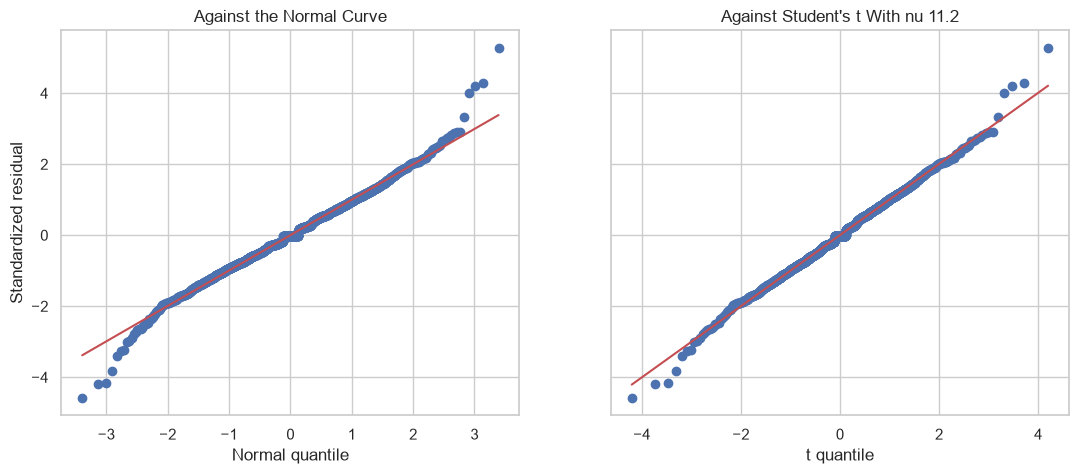

In [34]:
# the standardized residuals against the normal curve and against the fitted t (Course 4's Q-Q plot)
# sparams= hands probplot the t's shape: nu, a centre of 0 and the scale above
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
stats.probplot(residuals, dist="norm", plot=axes[0])
stats.probplot(residuals, dist=stats.t, sparams=(nu, 0, scale), plot=axes[1])
axes[0].set(title="Against the Normal Curve", xlabel="Normal quantile", ylabel="Standardized residual")
axes[1].set(title=f"Against Student's t With nu {nu:.1f}", xlabel="t quantile", ylabel="")
plt.show()

### Interpretation of the Degrees of Freedom

The smaller nu, the heavier the tails; above about 30 a t is close to the normal curve.

At nu 11.2 the t puts 13.6 of 2,000 beyond 3, beside the 13 found; the normal curve puts 5.4.

On the Q-Q plot the normal curve's line misses both ends, and the t's line runs much closer to them.

## The Variance Model

`vol="Constant"` keeps one variance for every date.

`vol="ARCH"` with `p=1` drops the beta term: **ARCH(1)**.

`o=1` adds **GJR**'s weight **gamma** on the square of a negative shock.

`vol="EGARCH"` models the log of the variance; `p=2` or `q=2` adds a second lag.

`**setting` passes a dictionary's entries to a function as keyword arguments.

In [35]:
# seven variance models, normal shocks: each one's settings for arch_model, then its BIC
settings = {"constant": dict(vol="Constant"), "ARCH(1)": dict(vol="ARCH", p=1),
            "GARCH(1,1)": dict(vol="GARCH", p=1, q=1), "GJR": dict(vol="GARCH", p=1, o=1, q=1),
            "EGARCH": dict(vol="EGARCH", p=1, q=1), "GARCH(2,1)": dict(vol="GARCH", p=2, q=1),
            "GARCH(1,2)": dict(vol="GARCH", p=1, q=2)}
bic = {}
for label, setting in settings.items():
    vol_model = arch_model(ten.to_numpy(), mean="Constant", rescale=False, **setting)
    with threadpool_limits(limits=1):
        bic[label] = vol_model.fit(disp="off").bic
bic = pd.Series(bic)
print((bic - bic.min()).round(1).to_dict())

{'constant': 311.9, 'ARCH(1)': 197.1, 'GARCH(1,1)': 0.0, 'GJR': 7.6, 'EGARCH': 2.7, 'GARCH(2,1)': 7.6, 'GARCH(1,2)': 6.0}


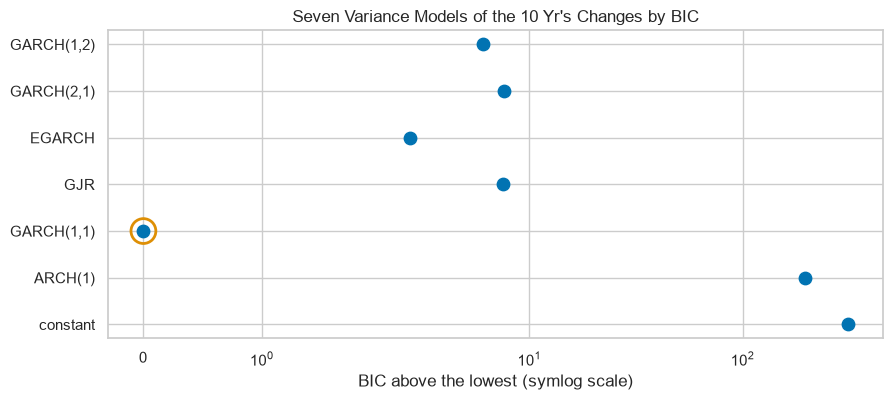

In [36]:
# each model's BIC above the lowest, the lowest ringed
gap = bic - bic.min()
plt.figure(figsize=(10, 4))
plt.scatter(gap, gap.index, s=80)
plt.scatter(0, gap.idxmin(), s=320, facecolors="none", edgecolors="C1", linewidths=2)
plt.xscale("symlog")
plt.xlabel("BIC above the lowest (symlog scale)")
plt.title("Seven Variance Models of the 10 Yr's Changes by BIC")
plt.show()

GARCH(1,1) has the lowest BIC; every model with more terms sits within 8 of it.

The constant variance sits over 300 above: one variance for all eight years fits worst by far.

## Rises Against Falls

A **news-impact curve** draws the next row's variance against today's shock, with today's variance at its long-run level.

In [37]:
# GJR on the 10 Yr and on IG: gamma, and the BIC with gamma and without
gjr = {}
for name in ["10 Yr", "IG"]:
    gjr_model = arch_model(changes[name].to_numpy(), mean="Constant", vol="GARCH", p=1, o=1, q=1, rescale=False)
    with threadpool_limits(limits=1):
        gjr[name] = gjr_model.fit(disp="off")
    print(name, "| gamma:", round(gjr[name].params["gamma[1]"], 3), "| BIC with gamma:", round(gjr[name].bic, 1),
          "| without:", round(plain_bic[name], 1))

10 Yr | gamma: 0.003 | BIC with gamma: 11846.1 | without: 11838.6
IG | gamma: -0.078 | BIC with gamma: 5814.1 | without: 5814.6


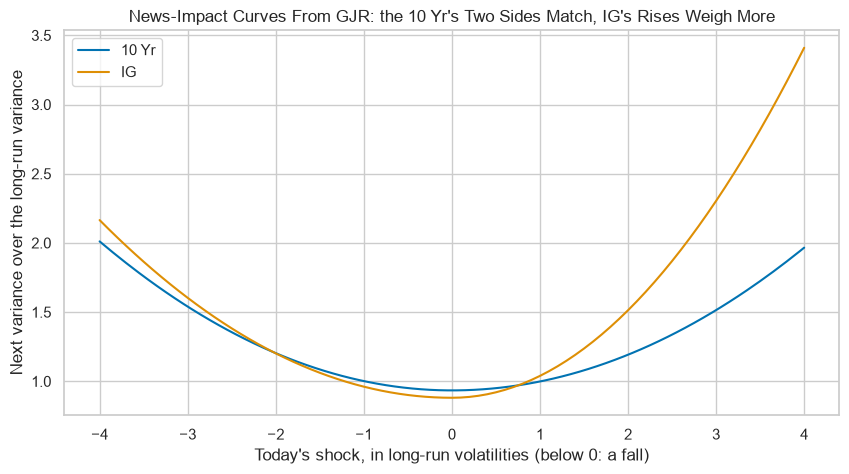

In [38]:
# the next variance against a shock of -4 to 4 long-run volatilities, as a multiple of the long-run variance
shock = np.linspace(-4, 4, 161)
for name in ["10 Yr", "IG"]:
    p = gjr[name].params
    long_run = p["omega"] / (1 - p["alpha[1]"] - p["gamma[1]"] / 2 - p["beta[1]"])
    weight = p["alpha[1]"] + p["gamma[1]"] * (shock < 0)
    plt.plot(shock, (p["omega"] + weight * shock ** 2 * long_run + p["beta[1]"] * long_run) / long_run, label=name)
plt.xlabel("Today's shock, in long-run volatilities (below 0: a fall)")
plt.ylabel("Next variance over the long-run variance")
plt.title("News-Impact Curves From GJR: the 10 Yr's Two Sides Match, IG's Rises Weigh More")
plt.legend()
plt.show()

The 10 Yr's gamma is near 0: a rise and a fall of the same size stir the same variance.

IG's gamma is negative, so a widening adds more variance than a tightening, and its BIC barely changes.

**Student's t for the shocks and GARCH(1,1) for the variance fit best by BIC; scoring keeps normal shocks, so the size has one simple formula.**

# Walk-Forward Scoring

For a normal shock the average size is sqrt(2 / pi), about 0.798, times its volatility.
So GARCH's value for the size of a date is 0.798 times its volatility: a value for the size, as Day 6's EWMA of the size is one, and scored as Day 6 scored it, by MAE in bp against the size that happened.

In [39]:
# the average size of a normal draw, by the formula and from 100,000 draws
print(round(np.sqrt(2 / np.pi), 4), round(np.abs(rng.standard_normal(100000)).mean(), 4))

0.7979 0.7994


## One Fit a Fold

Each fold fits GARCH(1,1) on its training changes, then `garch_path` runs those numbers through the fold's last test date, so each test date's volatility reads only the rows before it.

In [40]:
# walk forward on one series: each fold fits GARCH(1,1) on its training changes, the recursion runs to its last test date
def walk_forward_size(name, folds):
    """Each test date's size, its values from GARCH, the training mean and Day 6's EWMA; each fold's alpha and beta."""
    values, ewma = changes[name].to_numpy(), changes[name].abs().ewm(alpha=0.06, adjust=False).mean().shift(1)
    rows, coefficients = [], []
    for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
        fold_model = arch_model(values[fit_rows], mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
        with threadpool_limits(limits=1):
            fold_fit = fold_model.fit(disp="off")
        mu_fold, omega_fold, alpha_fold, beta_fold = fold_fit.params
        path = garch_path(values[:test_rows[-1] + 1], mu_fold, omega_fold, alpha_fold, beta_fold, fold_fit.conditional_volatility[0] ** 2)
        rows.append(pd.DataFrame({"fold": fold, "size": np.abs(values[test_rows]), "GARCH": np.sqrt(2 / np.pi) * path[test_rows],
                                  "training mean": np.abs(values[fit_rows]).mean(), "Day 6's EWMA": ewma.iloc[test_rows]}))
        coefficients.append([alpha_fold, beta_fold])
    return pd.concat(rows), pd.DataFrame(coefficients, columns=["alpha", "beta"], index=range(1, len(folds) + 1))

In [41]:
# the 10 Yr walked forward: each fold's alpha and beta, persistence and half-life in rows
walk, fold_numbers = walk_forward_size("10 Yr", folds)
fold_numbers["persistence"] = fold_numbers["alpha"] + fold_numbers["beta"]
fold_numbers["half-life"] = np.log(0.5) / np.log(fold_numbers["persistence"])
fold_numbers.round(3)

,alpha,beta,persistence,half-life
1,0.000,0.998,0.998,409.445
2,0.000,0.997,0.997,268.985
3,0.010,0.985,0.995,147.784
4,0.087,0.850,0.937,10.598
5,0.081,0.856,0.937,10.625


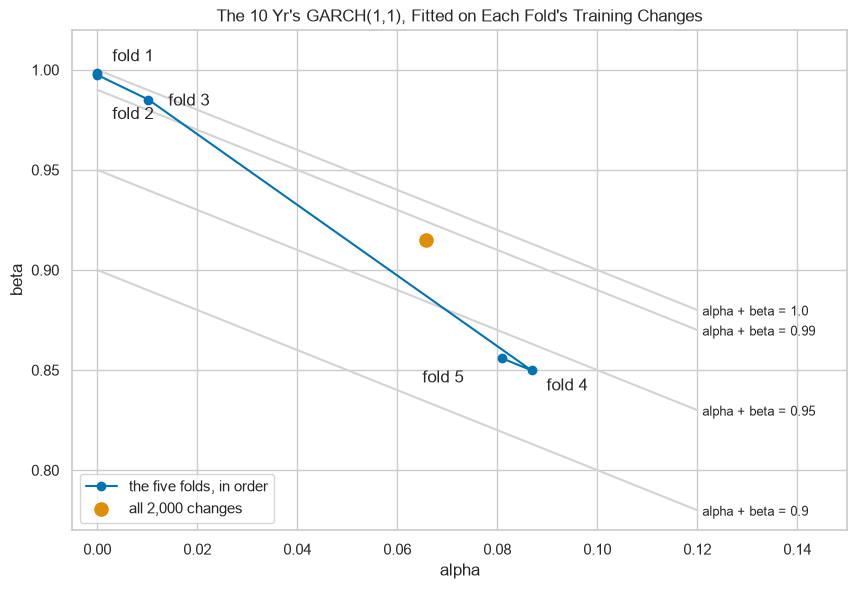

In [42]:
# each fold's alpha and beta, joined in fold order, over lines of equal persistence
grid = np.linspace(0, 0.12, 50)
plt.figure(figsize=(10, 6.5))
for level in [0.90, 0.95, 0.99, 1.0]:
    plt.plot(grid, level - grid, color="lightgray")
    plt.text(0.121, level - 0.121, f"alpha + beta = {level}", fontsize=9, va="center")
plt.plot(fold_numbers["alpha"], fold_numbers["beta"], color="C0", marker="o", label="the five folds, in order")
for fold, (dx, dy) in zip(fold_numbers.index, [(0.003, 0.006), (0.003, -0.022), (0.004, -0.003), (0.003, -0.01), (-0.016, -0.012)]):
    plt.text(fold_numbers.loc[fold, "alpha"] + dx, fold_numbers.loc[fold, "beta"] + dy, f"fold {fold}")
plt.scatter(alpha, beta, color="C1", s=90, zorder=3, label="all 2,000 changes")
plt.xlim(-0.005, 0.15)
plt.ylim(0.77, 1.02)
plt.xlabel("alpha")
plt.ylabel("beta")
plt.title("The 10 Yr's GARCH(1,1), Fitted on Each Fold's Training Changes")
plt.legend(loc="lower left")
plt.show()

Folds 1 and 2, fitted on the years to 2017 and to 2018, put alpha at 0: no clustering in those fits, and a near-constant volatility.

Folds 4 and 5 move to alpha 0.08 and a persistence near 0.94, a half-life of 10.6 rows, once 2020 is in the training years.

## The Scores Beside Day 6's

In [43]:
# the last size carried forward joins the other three; then each rule's MAE by fold, in bp
walk["last size"] = size.shift(1)
misses = walk.drop(columns=["fold", "size"]).sub(walk["size"], axis=0).abs()
size_scores = misses.groupby(walk["fold"]).mean()
size_scores.loc["average"] = size_scores.mean()
size_scores.round(3)

,GARCH,training mean,Day 6's EWMA,last size
fold,,,,
1,1.657,1.916,1.706,2.365
2,2.089,2.098,2.134,2.754
3,2.723,2.566,2.454,2.933
4,2.036,2.047,2.041,2.829
5,3.382,3.814,3.462,4.976
average,2.377,2.488,2.359,3.171


In [44]:
# GARCH against the training mean: folds closer, the average gap, and how far the training mean's folds spread, in bp
gap = size_scores["training mean"] - size_scores["GARCH"]
spread = size_scores["training mean"].iloc[:5].max() - size_scores["training mean"].iloc[:5].min()
print("GARCH closer in", (gap.iloc[:5] > 0).sum(), "of 5 folds | average gap:", round(gap["average"], 3),
      "bp | fold range of the training mean:", round(spread, 3), "bp")

GARCH closer in 4 of 5 folds | average gap: 0.111 bp | fold range of the training mean: 1.899 bp


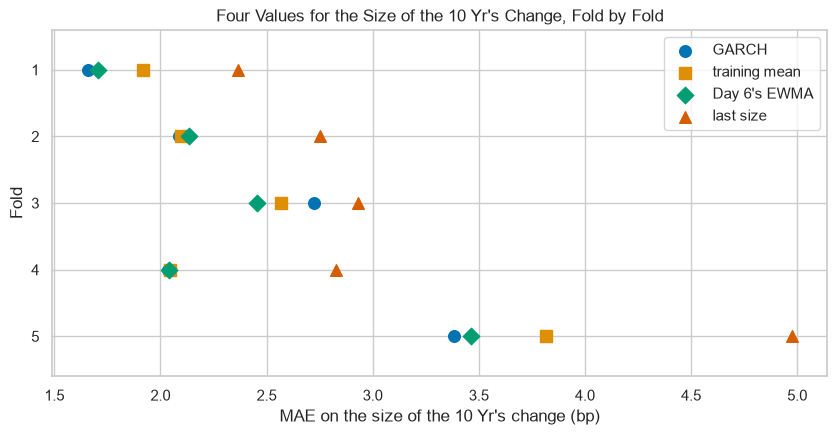

In [45]:
# each rule's MAE in each fold
fig, ax = plt.subplots(figsize=(10, 4.5))
for rule, marker in zip(size_scores.columns, ["o", "s", "D", "^"]):
    ax.scatter(size_scores[rule].iloc[:5], range(1, 6), marker=marker, s=70, label=rule)
ax.set(yticks=range(1, 6), ylim=(5.6, 0.4), xlabel="MAE on the size of the 10 Yr's change (bp)", ylabel="Fold")
ax.set_title("Four Values for the Size of the 10 Yr's Change, Fold by Fold")
ax.legend(loc="upper right")
plt.show()

GARCH misses by 2.377 bp on average, the training mean by 2.488, Day 6's EWMA by 2.359, and the last size by 3.171.

GARCH is closer than the training mean in 4 of 5 folds, by 0.111 bp on average: about 4.5 percent.

The training mean's own folds spread over 1.899 bp, so by Day 2's rule the gain is inside the folds' disagreement.

## A Series Where the Volatility Is Known

Q. Is a gain this small GARCH's fault, or the score's?

**Predict 4**

Below, 2,000 changes are drawn from the 10 Yr's fitted GARCH(1,1), so the true volatility of every row is known.

Q. Scored on the size, how much closer than one constant is the true volatility, in percent? Write down a number.

## Scoring the True Volatility

In [46]:
# 2,000 changes from the 10 Yr's fitted numbers, keeping each row's true volatility, in bp
true_volatility, simulated = [np.sqrt(omega / (1 - persistence))], []
for draw in rng.standard_normal(2000):
    simulated.append(true_volatility[-1] * draw)
    true_volatility.append(np.sqrt(omega + alpha * simulated[-1] ** 2 + beta * true_volatility[-1] ** 2))
true_volatility, simulated_size = np.array(true_volatility[:-1]), np.abs(simulated)

In [47]:
# the true volatility's value for the size against one constant, the average size, in bp
true_mae = mean_absolute_error(simulated_size, np.sqrt(2 / np.pi) * true_volatility)
constant_mae = mean_absolute_error(simulated_size, 0 * simulated_size + simulated_size.mean())
print("True volatility:", round(true_mae, 3), "bp | constant:", round(constant_mae, 3), "bp | closer by",
      round((1 - true_mae / constant_mae) * 100, 1), "percent")

True volatility: 2.474 bp | constant: 2.602 bp | closer by 4.9 percent


### Interpretation of the True Volatility's Score

Even the true volatility is only 4.9 percent closer than a constant: one day's size is mostly the luck of that day's shock.

So an MAE on single sizes barely tells a good volatility from a flat one, and GARCH's 4.5 percent on the 10 Yr is near what the truth itself earned in this draw.

## Sorting Calm Days From Stormy Ones

In [48]:
# the 1,260 scored dates in ten groups by GARCH's value, lowest first: each group's average value and size, in bp
tenth = pd.qcut(walk["GARCH"], 10, labels=range(1, 11))
sorted_days = walk.groupby(tenth, observed=True)[["GARCH", "size"]].mean()
print("Correlation of GARCH's value and the size:", round(walk["GARCH"].corr(walk["size"]), 3))
sorted_days.round(2).T

Correlation of GARCH's value and the size: 0.315


GARCH,1,2,3,4,5,6,7,8,9,10
GARCH,2.17,2.40,2.48,2.53,3.01,3.36,3.60,4.23,4.89,5.94
size,2.48,3.23,3.61,2.92,3.35,3.06,3.53,4.59,6.00,5.95


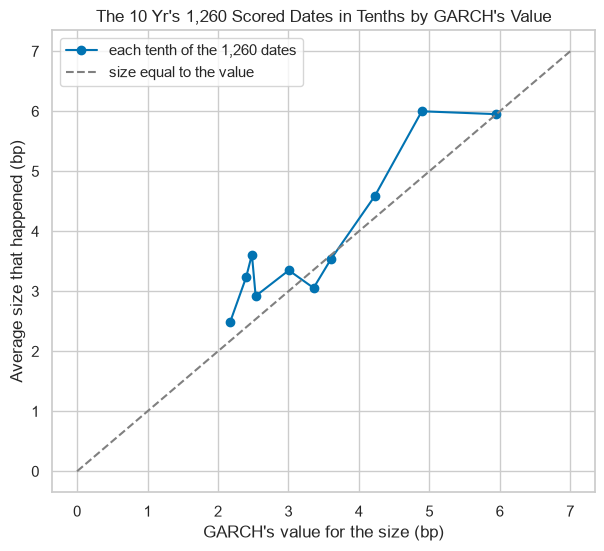

In [49]:
# each tenth's average size against its average value, with the line where the two are equal
plt.figure(figsize=(7, 6))
plt.plot(sorted_days["GARCH"], sorted_days["size"], marker="o", label="each tenth of the 1,260 dates")
plt.plot([0, 7], [0, 7], color="gray", linestyle="--", label="size equal to the value")
plt.xlabel("GARCH's value for the size (bp)")
plt.ylabel("Average size that happened (bp)")
plt.title("The 10 Yr's 1,260 Scored Dates in Tenths by GARCH's Value")
plt.legend()
plt.show()

The calmest tenth averaged 2.48 bp and the stormiest 5.95: on dates it never saw, GARCH's higher tenths hold the larger days, though not in perfect order.

Eight of the ten tenths sit above the line: on these dates the sizes ran larger than GARCH's values.

**GARCH sorts calm days from stormy ones; on one day's size it is no closer than Day 6's EWMA, and its gain over a constant is inside the folds' disagreement.**

# The Level Against the Size

## Five Series

In [50]:
# every series walked forward: GARCH's size MAE over the training mean's and over Day 6's EWMA, folds closer, the gap and the fold range
rows = []
for name in changes.columns:
    series_walk, coefficients = walk_forward_size(name, folds)
    fold_mae = series_walk[["GARCH", "training mean", "Day 6's EWMA"]].sub(series_walk["size"], axis=0).abs().groupby(series_walk["fold"]).mean()
    rows.append({"series": name, "GARCH / mean": fold_mae["GARCH"].mean() / fold_mae["training mean"].mean(),
                 "GARCH / EWMA": fold_mae["GARCH"].mean() / fold_mae["Day 6's EWMA"].mean(),
                 "folds closer": int((fold_mae["GARCH"] < fold_mae["training mean"]).sum()),
                 "gap (bp)": (fold_mae["training mean"] - fold_mae["GARCH"]).mean(),
                 "fold range (bp)": fold_mae["training mean"].max() - fold_mae["training mean"].min()})
size_ratios = pd.DataFrame(rows).set_index("series")
size_ratios.round(3)

,GARCH / mean,GARCH / EWMA,folds closer,gap (bp),fold range (bp)
series,,,,,
2 Yr,0.909,1.023,5,0.210,2.871
10 Yr,0.955,1.008,4,0.111,1.899
2s10s,0.978,0.998,3,0.037,1.142
IG,0.968,0.976,4,0.019,0.409
HY,0.941,0.975,5,0.147,1.598


In [51]:
# the level of the change: Day 5's AR(1) fitted once a fold, its one-step values from .append(), MASE against the last value
mase = {}
for name in changes.columns:
    values, fold_maes, last_maes = changes[name].to_numpy(), [], []
    for fit_rows, test_rows in folds:
        ar1 = ARIMA(values[fit_rows], order=(1, 0, 0), trend="c").fit()
        one_step = ar1.append(values[test_rows], refit=False).predict(start=len(fit_rows), end=test_rows[-1])
        fold_maes.append(mean_absolute_error(values[test_rows], one_step))
        last_maes.append(np.abs(values[test_rows]).mean())
    mase[name] = np.mean(fold_maes) / np.mean(last_maes)
print({name: round(float(value), 4) for name, value in mase.items()})

{'2 Yr': 1.009, '10 Yr': 1.0035, '2s10s': 1.0049, 'IG': 1.0046, 'HY': 1.0042}


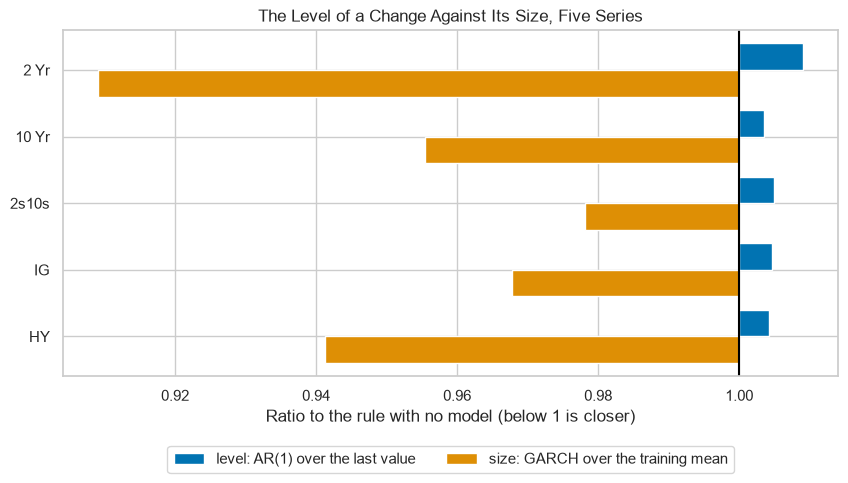

In [52]:
# per series: the level's ratio and the size's, around 1
both = pd.DataFrame({"level: AR(1) over the last value": pd.Series(mase),
                     "size: GARCH over the training mean": size_ratios["GARCH / mean"]})
fig, ax = plt.subplots(figsize=(10, 4.5))
for shift, column in zip([-0.2, 0.2], both.columns):
    ax.barh(np.arange(5) + shift, both[column] - 1, left=1, height=0.4, label=column)
ax.axvline(1, color="black")
ax.set(yticks=range(5), yticklabels=both.index, ylim=(4.6, -0.6), xlabel="Ratio to the rule with no model (below 1 is closer)")
ax.set_title("The Level of a Change Against Its Size, Five Series")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=2)
plt.show()

On the level, Day 5's AR(1) misses by more than the last value on every series.

On the size, GARCH misses by 2 to 9 percent less than the training mean on every series, closer in 3 to 5 folds of 5.

Every gap is smaller than the training mean's own fold range, so no series passes Day 2's rule.

Against Day 6's EWMA, GARCH is a little behind on the 2 Yr and 10 Yr and a little ahead on the other three.

**On the level of a change, the AR(1) is no closer than the last value; on its size, GARCH is closer than a constant on every series, by less than the folds disagree.**

# Insights and Conclusion

The 10 Yr's 100 largest days sat in 43 months where 100 random dates fill about 63: the size of a change clusters.

GARCH(1,1) writes that memory in three numbers; the 10 Yr's fitted persistence is 0.9809, a half-life of 35.9 trading days, and the 2 Yr's fit sits on 1, with no half-life.

Student's t shocks fit better than normal ones, and GARCH(1,1) beat six other variance models by BIC.

Walked forward, the first two folds' fits put alpha at 0, and the score on single sizes barely sees even the true volatility.

GARCH sorts calm days from stormy ones, and its gain over a constant on the size stays inside the folds' disagreement.

**Model the size, carry the level.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Measure whether a series' largest days scatter or cluster in time.
* Write the GARCH(1,1) recursion by hand and match arch's fitted volatility to the last digit.
* Fit `arch_model` and read omega, alpha, beta, persistence, half-life and long-run volatility.
* Choose the shock curve and the variance model by AIC and BIC, and read a news-impact curve.
* Score a volatility walk-forward on the size of a change, and set the size beside the level.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [53]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Shorter Window**

Q. Fit GARCH(1,1) to the 10 Yr's changes from 2020 on, `ten.loc["2020":]`, and store its half-life in rows in `ex1_half_life`.

In [54]:
# GARCH(1,1) on the 10 Yr's changes from 2020 on, then its half-life in rows
short_model = arch_model(ten.loc["2020":].to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
with threadpool_limits(limits=1):
    short_fit = short_model.fit(disp="off")
ex1_half_life = np.log(0.5) / np.log(short_fit.params["alpha[1]"] + short_fit.params["beta[1]"])
print(ex1_half_life)

68.58962175855058


In [55]:
check("Exercise 1 the half-life from 2020 on", ex1_half_life, 68.58962175855058)

Exercise 1 the half-life from 2020 on: correct


### Exercise 2

**A Function for the Long-Run Volatility**

Q. Write `long_run_volatility(omega, alpha, beta)`, which returns the long-run volatility in bp, and store HY's from the `five` table in `ex2_long_run`.

In [56]:
# the level the volatility settles at once the shocks die away, in bp
def long_run_volatility(omega, alpha, beta):
    return np.sqrt(omega / (1 - alpha - beta))

ex2_long_run = long_run_volatility(five.loc["HY", "omega"], five.loc["HY", "alpha[1]"], five.loc["HY", "beta[1]"])
print(ex2_long_run)

4.851384732203125


In [57]:
check("Exercise 2 HY's long-run volatility", ex2_long_run, 4.851384732203125)

Exercise 2 HY's long-run volatility: correct


### Exercise 3

**A Rolling Training Window**

Course 4's `max_train_size=504` keeps only the last 504 training changes in each fold.

Q. Walk GARCH forward on the 10 Yr with `TimeSeriesSplit(n_splits=5, test_size=252, max_train_size=504)`, and store its average fold MAE on the size in `ex3_mae`.

In [58]:
# the same walk forward, each fold keeping only its last 504 training changes
short_folds = list(TimeSeriesSplit(n_splits=5, test_size=252, max_train_size=504).split(changes))
short_walk, short_numbers = walk_forward_size("10 Yr", short_folds)
ex3_mae = mean_absolute_error(short_walk["size"], short_walk["GARCH"])
print(ex3_mae)

2.341016041098963


In [59]:
check("Exercise 3 GARCH's MAE with 504 training changes", ex3_mae, 2.341016041098963)

Exercise 3 GARCH's MAE with 504 training changes: correct


### Exercise 4

**IG's Tails**

Q. Fit GARCH(1,1) with Student's t shocks to IG's changes, and store its nu in `ex4_nu`.

In [60]:
# GARCH(1,1) with Student's t shocks on IG's changes, then its nu
ig_model = arch_model(changes["IG"].to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False)
with threadpool_limits(limits=1):
    ig_fit = ig_model.fit(disp="off")
ex4_nu = ig_fit.params["nu"]
print(ex4_nu)

11.622345662022543


In [61]:
check("Exercise 4 IG's nu", ex4_nu, 11.622345662022543)

Exercise 4 IG's nu: correct


### Exercise 5: AI check

**The Volatility That Looked Too Big**

You asked an AI assistant for a function that gives each date's GARCH volatility from a series of levels in bp.
This came back, with a test in its docstring.
Run the test on a random walk of levels, then find the one bug.

In [62]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def fitted_volatility(level):
    """Each date's GARCH(1,1) volatility in bp, from a series of levels in bp.
    Test: the average volatility sits within 20 percent of the standard deviation of the daily changes."""
    model = arch_model(level.to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
    with threadpool_limits(limits=1):
        result = model.fit(disp="off")
    return pd.Series(result.conditional_volatility, index=level.index)

In [63]:
# a random walk of 800 levels in bp from a fresh generator, and the function's average against the changes' spread
walk_rng = np.random.default_rng(SEED)
level = pd.Series(300 + np.cumsum(3 * walk_rng.standard_normal(800)))
print("Average volatility:", round(fitted_volatility(level).mean(), 2), "bp | standard deviation of the changes:",
      round(level.diff().std(), 3), "bp")

Average volatility: 21.15 bp | standard deviation of the changes: 2.955 bp


In [64]:
# the docstring's test
assert abs(fitted_volatility(level).mean() / level.diff().std() - 1) < 0.2, \
    "the average volatility is far from the size of the daily changes"

AssertionError: the average volatility is far from the size of the daily changes

Q. Fix the one wrong line, and store the fixed function's average volatility on `level` in `ex5_vol`.

In [65]:
# the fix: fit the daily changes, level.diff().dropna(), not the levels
def fitted_volatility(level):
    """Each date's GARCH(1,1) volatility in bp, from a series of levels in bp."""
    change = level.diff().dropna()
    model = arch_model(change.to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
    with threadpool_limits(limits=1):
        result = model.fit(disp="off")
    return pd.Series(result.conditional_volatility, index=change.index)

ex5_vol = fitted_volatility(level).mean()
print(ex5_vol)

2.950416266835194


In [66]:
check("Exercise 5 the fixed average volatility", ex5_vol, 2.950416266835194)

Exercise 5 the fixed average volatility: correct


## Congratulations!

You found the memory in the size of a change and wrote it down as one recursion with three numbers.
You matched arch's 2,000 volatilities with five lines of your own, fitted five series, and read how long each one's storms last.
You chose the shock curve and the variance model by evidence, and walked GARCH forward on dates it never saw.
You also learned how little one day's size can tell, which keeps your verdicts honest.
In Day 8 you hand LightGBM many inputs about the past at once, and the cut test catches a leak on purpose.

[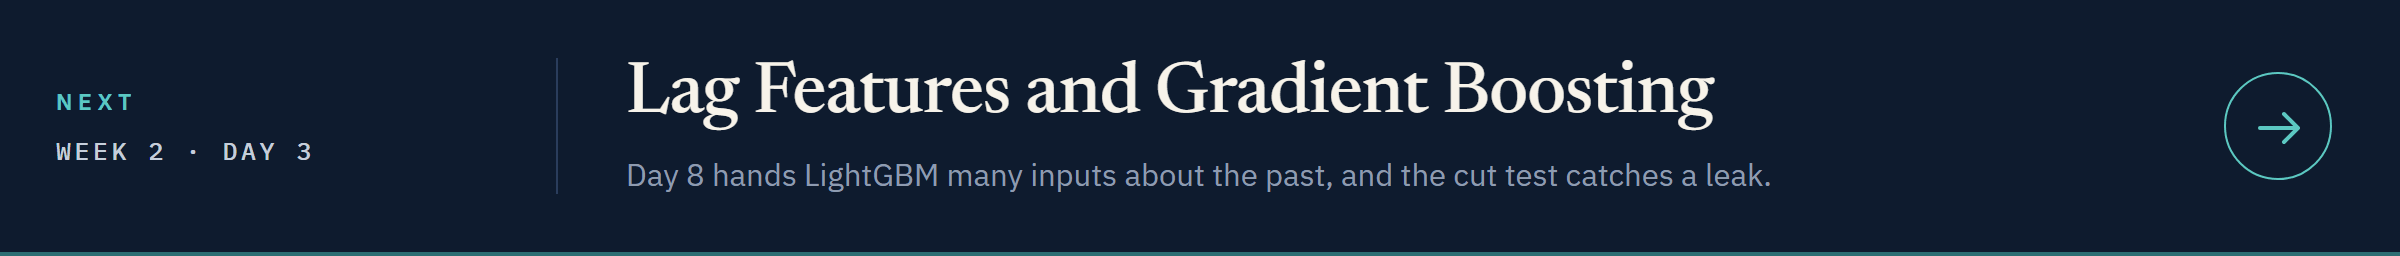](../day3/08_lag_features_and_gradient_boosting.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day3/08_lag_features_and_gradient_boosting.ipynb)